# Ji et al. 2020 — Cutaneous SCC · 03 Signatures

Embryonic-module signatures (Gast, pSom, Crest) scored with the union control pool, projected on the branching manifold. **Gate 2 (module geography):** does a Gast/pSom hub diverge into two arms with Crest terminal?

In [1]:
import os, glob, sys
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt

In [2]:
name = os.path.split(os.getcwd())[1]
pth = os.path.join('..', '..', '..', '..', '..', '..')
pth_data = os.path.join(pth, 'data')
pth_in  = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', 'Skin', name)
pth_feat = os.path.join(pth_data, 'features', 'biomart')
pth_out = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', 'Skin', name)
pth_cb = os.path.join(pth_out, 'colorbars')

### Load manifold

In [3]:
adata = sc.read_h5ad(os.path.join(pth_in, 'manifold.h5ad')); adata

AnnData object with n_obs × n_vars = 6800 × 1443
    obs: 'sample', 'cell_type', 'complexity', 'umap1', 'umap2', 'g1s_score', 'g2m_score', 'cell_cycle_phase', 'mp_top_score', 'mp_top', 'mp_assignment', 'source', 'cell_subtype_level1', 'cell_subtype_level2', 'celltype', 'leiden', 'GSE162534', 'GSE229103', 'rRNAModifications', 'GSE162534_sm', 'GSE229103_sm', 'rRNAModifications_sm', 't', 'seg', 'edge', 'milestones'
    var: 'n_cells', 'm', 'v', 'n_obs', 'res', 'lp', 'lpa', 'qv', 'highly_variable'
    uns: 'cell_cycle_phase_colors', 'celltype_colors', 'graph', 'leiden', 'leiden_colors', 'log1p', 'milestones_colors', 'neighbors', 'pca', 'ppt', 'pseudotime_list', 'sample_colors', 'seg_colors', 'umap'
    obsm: 'X_R', 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

### Score embryonic modules
Scores were computed in 02 (union control pool, `ctrl_as_ref=False`). Confirm the recovered gene counts and reuse the stored scores; smoothed variants (`*_sm`) are used for geography.

In [4]:
feat_fn = sorted(glob.glob(os.path.join(pth_feat, '*.csv')))
get_src = lambda fn: os.path.split(fn)[1].replace('.csv', '')
get_feat = lambda fn: pd.read_csv(fn).hsapiens.drop_duplicates()
feat_dict = {get_src(fn): get_feat(fn) for fn in feat_fn}
g_ref = feat_dict['union'].loc[feat_dict['union'].isin(adata.raw.var_names)]
for src in ['GSE162534', 'GSE229103', 'rRNAModifications']:
    g = feat_dict[src].loc[feat_dict[src].isin(adata.raw.var_names)]
    print(src, g.size, g_ref.size)

GSE162534 76 224
GSE229103 88 224
rRNAModifications 101 224


### Gastrulation (Gast) signature
Gast is high at the **Gast/pSom hub** and along the **Gast-arm** (relative to other states).

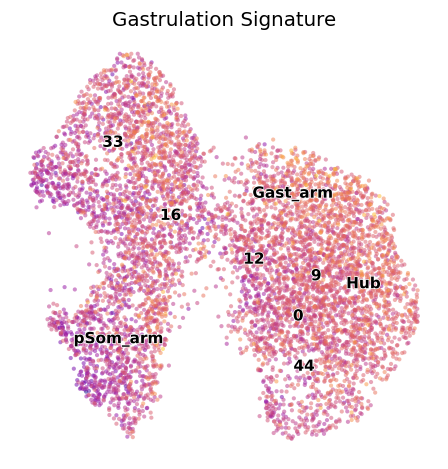

In [5]:
fig, ax = plt.subplots(1, 1, figsize = (5, 5))
sc.pl.umap(adata, color = 'GSE162534', cmap = 'plasma', alpha = .5, size = 30,
           colorbar_loc = None, frameon = False, show = False, ax = ax)
sc.pl.umap(adata, color = 'milestones', size = 30, alpha = 0, legend_loc = 'on data',
           legend_fontoutline = 1, frameon = False, show = False, ax = ax)
ax.invert_yaxis(); ax.invert_xaxis()
ax.set_title('Gastrulation Signature', size = 13)
fig.savefig(os.path.join(pth_out, 'Gast_signature.pdf'), bbox_inches = 'tight')

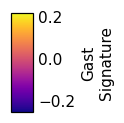

In [6]:
fig = plt.figure(figsize = (.66, 1)); cax = fig.add_axes([.35, .05, .3, .9])
cb = plt.colorbar(ax.collections[0], cax = cax); cb.ax.tick_params(which='both', size=0)
cb.set_label('Gast\nSignature'); cb.solids.set_alpha(1)
fig.savefig(os.path.join(pth_cb, 'Gast_colorbar.pdf'), bbox_inches = 'tight')

### Posterior somitogenesis (pSom) signature
pSom peaks on the **pSom-arm** terminal (TSK leading-edge), diverging from the hub opposite to Gast.

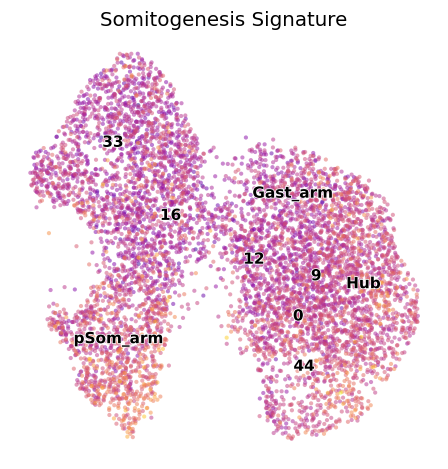

In [7]:
fig, ax = plt.subplots(1, 1, figsize = (5, 5))
sc.pl.umap(adata, color = 'GSE229103', cmap = 'plasma', alpha = .5, size = 30,
           colorbar_loc = None, frameon = False, show = False, ax = ax)
sc.pl.umap(adata, color = 'milestones', size = 30, alpha = 0, legend_loc = 'on data',
           legend_fontoutline = 1, frameon = False, show = False, ax = ax)
ax.invert_yaxis(); ax.invert_xaxis()
ax.set_title('Somitogenesis Signature', size = 13)
fig.savefig(os.path.join(pth_out, 'pSom_signature.pdf'), bbox_inches = 'tight')

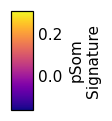

In [8]:
fig = plt.figure(figsize = (.66, 1)); cax = fig.add_axes([.35, .05, .3, .9])
cb = plt.colorbar(ax.collections[0], cax = cax); cb.ax.tick_params(which='both', size=0)
cb.set_label('pSom\nSignature'); cb.solids.set_alpha(1)
fig.savefig(os.path.join(pth_cb, 'pSom_colorbar.pdf'), bbox_inches = 'tight')

### Neural crest (Crest) signature
Crest is a **terminal readout** — low at the Gast/pSom hub, high toward the arm tips (the Crest-high leading-edge / basal states). It is not on the Gast<->pSom cross-repression axis.

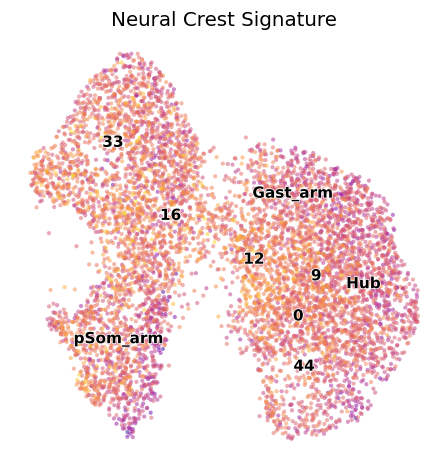

In [9]:
fig, ax = plt.subplots(1, 1, figsize = (5, 5))
sc.pl.umap(adata, color = 'rRNAModifications', cmap = 'plasma', alpha = .5, size = 30,
           colorbar_loc = None, frameon = False, show = False, ax = ax)
sc.pl.umap(adata, color = 'milestones', size = 30, alpha = 0, legend_loc = 'on data',
           legend_fontoutline = 1, frameon = False, show = False, ax = ax)
ax.invert_yaxis(); ax.invert_xaxis()
ax.set_title('Neural Crest Signature', size = 13)
fig.savefig(os.path.join(pth_out, 'Crest_signature.pdf'), bbox_inches = 'tight')

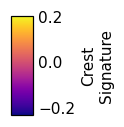

In [10]:
fig = plt.figure(figsize = (.66, 1)); cax = fig.add_axes([.35, .05, .3, .9])
cb = plt.colorbar(ax.collections[0], cax = cax); cb.ax.tick_params(which='both', size=0)
cb.set_label('Crest\nSignature'); cb.solids.set_alpha(1)
fig.savefig(os.path.join(pth_cb, 'Crest_colorbar.pdf'), bbox_inches = 'tight')

### Gate 2 verdict
**GO (branching).** Gast and pSom emanate from a shared Gast/pSom-high hub toward opposite terminals (Gast-arm vs pSom-arm), with Crest high toward the arm tips. Hub cross-repression is quantified in 04/05.

In [11]:
adata.write(os.path.join(pth_in, 'signatures.h5ad'))